# Did GD find the construction's QK circuit?

`train_qk_only.py` freezes everything except the QK circuit: OV is pinned to the hand
construction in both layers, the readout is a fixed identity selector with a fixed
pre-log bias, and the log is the log function. The only free parameters are

    combined : W_qk                      58,320
    separate : Wq, Wk                    69,984

so this asks one question cleanly: **given a perfect value/readout circuit, does gradient
descent recover the induction head's attention pattern?**

Cell: `qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000`, all 7 thresholds, both
architectures, 1000 epochs.

### How to compare, and what NOT to compare

**Never compare `Wq` and `Wk` entrywise.** They are defined only up to an invertible
transform: $(W_Q, W_K)\to(M^{-\top}W_Q,\,MW_K)$ leaves $W_Q^\top W_K$ — and therefore the
whole function — unchanged. Only the product is meaningful. So both architectures are reduced
to their effective

$$W_{qk}=W_Q^\top W_K$$

and compared against the construction's collapse of the same form (verified exact in folder 16).

Even $W_{qk}$ is not unique. The softmax leaves two further gauges:

| gauge | effect on scores | effect on $W_{qk}$ |
|---|---|---|
| temperature | $s\to\sigma s$ | $W_{qk}\to\sigma W_{qk}$ |
| per-query shift | $s_{ij}\to s_{ij}+a_i$ | $W_{qk}\to W_{qk}+u\,v^\top$ for any $v$ with $x_jv^\top$ constant |

A raw entrywise comparison will therefore look bad even for an identical function. The notebook
reports three levels: raw, gauge-quotiented, and — the one that actually settles it —
**functional agreement of the attention patterns on real data**.

## 1. Setup, checkpoints, and the construction

In [1]:
import glob, importlib.util, json, os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

_s = importlib.util.spec_from_file_location('qk', 'train_qk_only.py')
QK = importlib.util.module_from_spec(_s); _s.loader.exec_module(QK)

CELL = 'qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000'
CDIR = os.path.join('runs', CELL)
DATA = 'dataset'
ART  = os.path.join('artifacts', CELL); os.makedirs(ART, exist_ok=True)

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
TS, TE = QK.CFG['token_start'], T
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ARCHS = ['separate', 'combined']
THRS = sorted(float(p.split('_x_')[1][:-4])
              for p in glob.glob(os.path.join(CDIR, 'model_separate_*.pth')))

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'font.size': 12,
                     'axes.titlesize': 12, 'axes.labelsize': 11, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'legend.fontsize': 10, 'figure.titlesize': 14,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})

def load(arch, thr):
    m = QK.QKOnlyTransformer(V, T, D, VS, thr, arch).to(DEV)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_{arch}_seed0_x_{thr}.pth'),
                                 map_location=DEV, weights_only=True))
    return m.eval()

def eff_qk(model):
    '''The gauge-free QK circuit of either architecture.'''
    out = []
    for layer in (model.layer1, model.layer2):
        out.append(layer.W_qk.detach() if hasattr(layer, 'W_qk')
                   else (layer.W_q.weight.detach().t() @ layer.W_k.weight.detach()))
    return out

def eff_ov(model):
    out = []
    for layer in (model.layer1, model.layer2):
        out.append(layer.W_ov.detach() if hasattr(layer, 'W_ov')
                   else (layer.W_v.weight.detach().t() @ layer.W_o.weight.detach().t()))
    return out

def construction():
    Wq1 = torch.eye(D, device=DEV) * (D ** 0.5)
    M = torch.zeros(D, D, device=DEV)
    for k in range(VS, V):
        M[k, :] = -1e9
    for tq in range(T):
        for tk in range(T):
            M[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
    Wk1 = M.t()
    Wv1 = torch.zeros(D, D, device=DEV); Wv1[:V, :V] = torch.eye(V, device=DEV)
    Wo1 = torch.eye(D, device=DEV)
    Wq2 = torch.zeros(D, IN2, device=DEV)
    Wq2[:VS, :VS] = torch.eye(VS, device=DEV) * (D ** 0.5) * 1000.0
    Wq2[:VS, D:D + VS] = torch.eye(VS, device=DEV) * (D ** 0.5) * 50.0
    for v in range(V):
        Wq2[VS, v] = (D ** 0.5) * 10.0
    Wk2 = torch.zeros(D, IN2, device=DEV); Wk2[:V, D:D + V] = torch.eye(V, device=DEV)
    for v in range(VS, V):
        Wk2[VS, v] = -50000.0
    Wv2 = torch.zeros(D, IN2, device=DEV); Wv2[:V, :V] = torch.eye(V, device=DEV)
    Wo2 = torch.eye(D, device=DEV)
    return ([Wq1.t() @ Wk1, Wq2.t() @ Wk2], [Wv1.t() @ Wo1.t(), Wv2.t() @ Wo2.t()])

CQK, COV = construction()
print(f'cell   : {CELL}')
print(f'archs  : {ARCHS}   thresholds: {THRS}   device: {DEV}')
for i, (a, b) in enumerate(zip(CQK, COV), 1):
    print(f'  construction layer{i}: W_qk {tuple(a.shape)} nnz {int((a!=0).sum()):6d}   '
          f'W_ov {tuple(b.shape)} nnz {int((b!=0).sum())}')

cell   : qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000
archs  : ['separate', 'combined']   thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   device: cuda
  construction layer1: W_qk (108, 108) nnz  10432   W_ov (108, 108) nnz 8
  construction layer2: W_qk (216, 216) nnz     48   W_ov (216, 108) nnz 8


## 2. `W_ov` — the frozen half

`W_ov` was pinned to the construction and never trained, so this is a check that the freeze
actually held for the whole run, in both parametrizations. In `separate` it is stored as the
factors `Wv, Wo`, so the check is that their product still equals the construction.

In [2]:
print(f'{"arch":9s} {"thr":>4s} {"layer":>6s} {"max|W_ov - constr|":>20s} {"identical":>10s}')
worst_ov = 0.0
for arch in ARCHS:
    for thr in THRS:
        for i, ov in enumerate(eff_ov(load(arch, thr)), 1):
            d = float((ov - COV[i - 1]).abs().max())
            worst_ov = max(worst_ov, d)
            print(f'{arch:9s} {thr:4.1f} {i:6d} {d:20.2e} {str(torch.equal(ov, COV[i-1])):>10s}')
print(f'\nworst deviation anywhere: {worst_ov:.2e}  -> the OV circuit is the construction, exactly')

arch       thr  layer   max|W_ov - constr|  identical
separate   0.4      1             0.00e+00       True
separate   0.4      2             0.00e+00       True
separate   0.5      1             0.00e+00       True
separate   0.5      2             0.00e+00       True
separate   0.6      1             0.00e+00       True
separate   0.6      2             0.00e+00       True


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


separate   0.7      1             0.00e+00       True
separate   0.7      2             0.00e+00       True
separate   0.8      1             0.00e+00       True
separate   0.8      2             0.00e+00       True
separate   0.9      1             0.00e+00       True
separate   0.9      2             0.00e+00       True
separate   1.0      1             0.00e+00       True
separate   1.0      2             0.00e+00       True
combined   0.4      1             0.00e+00       True
combined   0.4      2             0.00e+00       True
combined   0.5      1             0.00e+00       True
combined   0.5      2             0.00e+00       True
combined   0.6      1             0.00e+00       True
combined   0.6      2             0.00e+00       True
combined   0.7      1             0.00e+00       True
combined   0.7      2             0.00e+00       True


combined   0.8      1             0.00e+00       True
combined   0.8      2             0.00e+00       True
combined   0.9      1             0.00e+00       True
combined   0.9      2             0.00e+00       True
combined   1.0      1             0.00e+00       True
combined   1.0      2             0.00e+00       True

worst deviation anywhere: 0.00e+00  -> the OV circuit is the construction, exactly


## 3. `W_qk` — raw, then gauge-quotiented

`cos` is the cosine between flattened matrices (already scale-invariant). `cos (shift-free)`
removes the per-query additive gauge first, by projecting out the component of each matrix that
adds a constant to a whole score row — that component is invisible to the softmax and should not
count against agreement.

In [3]:
def strip_shift(W, d_tok, d_pos):
    '''Remove the per-query additive gauge.

    A term u v^T contributes  x_i u (v . x_j)  to the score. With x_j = [tok one-hot ; pos
    one-hot], v . x_j is constant in j exactly when v is constant on the token block and
    constant on the position block. Projecting W's columns onto the orthogonal complement of
    that 2-dimensional span removes every such term.
    '''
    B = torch.zeros(2, W.shape[1], device=W.device)
    B[0, :d_tok] = 1.0
    B[1, d_tok:d_tok + d_pos] = 1.0
    if W.shape[1] > d_tok + d_pos:
        B = torch.cat([B, torch.zeros(2, 0, device=W.device)], 1)
    Q, _ = torch.linalg.qr(B.t())
    return W - (W @ Q) @ Q.t()

def cos(a, b):
    return float((a * b).sum() / (a.norm() * b.norm() + 1e-30))

L_DIMS = {1: (V, T, 0), 2: (V, T, D)}   # token, position, and the layer-1 output offset

print(f'{"arch":9s} {"thr":>4s} {"layer":>6s} {"cos raw":>9s} {"cos shift-free":>15s} '
      f'{"scale ratio":>12s} {"rank":>6s}')
COSD = {(a, i): [] for a in ARCHS for i in (1, 2)}
for arch in ARCHS:
    for thr in THRS:
        for i, qk in enumerate(eff_qk(load(arch, thr)), 1):
            c = CQK[i - 1]
            dt, dp, off = L_DIMS[i]
            cs = cos(strip_shift(qk, dt, dp + off if i == 2 else dp),
                     strip_shift(c,  dt, dp + off if i == 2 else dp))
            COSD[(arch, i)].append(cs)
            print(f'{arch:9s} {thr:4.1f} {i:6d} {cos(qk, c):9.4f} {cs:15.4f} '
                  f'{float(qk.norm()/c.norm()):12.2e} '
                  f'{int(torch.linalg.matrix_rank(qk.float())):6d}')
    print()

arch       thr  layer   cos raw  cos shift-free  scale ratio   rank


separate   0.4      1    0.2781          0.2612     7.72e-08    105
separate   0.4      2    0.0923          0.0723     5.69e-05    108
separate   0.5      1    0.2484          0.2369     7.10e-08    104


separate   0.5      2    0.0891          0.0691     5.66e-05    108
separate   0.6      1    0.2835          0.2622     6.14e-08    105
separate   0.6      2    0.0901          0.0698     6.87e-05    108


separate   0.7      1    0.2780          0.2505     5.23e-08    105
separate   0.7      2    0.1018          0.0781     5.67e-05    108
separate   0.8      1    0.2731          0.2362     4.36e-08    105


separate   0.8      2    0.0835          0.0636     6.54e-05    108
separate   0.9      1    0.1685          0.1398     3.62e-08    105
separate   0.9      2    0.0900          0.0698     4.82e-05    108
separate   1.0      1    0.0034          0.0058     1.57e-08    104


separate   1.0      2    0.0000          0.0001     3.99e-05    108

combined   0.4      1    0.3566          0.3582     1.99e-08    108
combined   0.4      2    0.1395          0.1205     3.12e-05    214
combined   0.5      1    0.3187          0.3254     2.20e-08    108


combined   0.5      2    0.1424          0.1212     3.32e-05    214
combined   0.6      1    0.2912          0.3029     2.31e-08    108
combined   0.6      2    0.1686          0.1388     3.33e-05    214
combined   0.7      1    0.2659          0.2750     2.26e-08    108
combined   0.7      2    0.1660          0.1348     3.49e-05    214


combined   0.8      1    0.1112          0.0883     1.23e-08    108
combined   0.8      2    0.1815          0.1476     3.05e-05    214
combined   0.9      1    0.0928          0.0749     1.13e-08    108
combined   0.9      2    0.1142          0.0911     3.67e-05    213


combined   1.0      1    0.0335          0.0252     9.79e-09    108
combined   1.0      2    0.0001          0.0004     4.81e-05    212



## 4. Functional agreement — the test that matters

Two attention heads are the same operator if they produce the same attention distribution. For
every scored query position, compare the learned head's softmax row against the construction's:

* **TV** — total-variation distance $\tfrac12\sum_k|p_k-q_k|$, 0 = identical, 1 = disjoint
* **argmax agree** — do they attend to the same key?
* **L1 hit** — does layer 1 attend to $t^*(t)$, the true previous-signal position?
* **L2 mass on $A_t$** — how much of layer 2's attention lands on the correct successor set
  $A_t=\{t_k<t:\ v_{t_k}<4,\ v^*(t_k)=v_t\}$, which is what makes $f$ a successor frequency

Note on layer 2: `argmax agree` is expected to be LOW even for a perfect head. $A_t$ typically
contains many positions and the construction spreads mass uniformly over all of them, so which
single one wins the argmax is arbitrary. **`L2 mass on $A_t$` is the meaningful metric there.**

In [4]:
@torch.no_grad()
def attn_rows(model, x):
    '''Both layers' attention matrices for one batch.'''
    B, Tn = x.shape
    tok = F.one_hot(x, num_classes=V).float()
    pos = F.one_hot(torch.arange(Tn, device=x.device), num_classes=T).float()
    pos = pos.unsqueeze(0).expand(B, Tn, -1)
    s = torch.cat([tok, pos], -1)
    mask = torch.triu(torch.ones(Tn, Tn, device=x.device) * float('-inf'), diagonal=1)
    out = []
    for layer in (model.layer1, model.layer2):
        if hasattr(layer, 'W_qk'):
            sc = torch.bmm(s @ layer.W_qk, s.transpose(1, 2))
            ov = s @ layer.W_ov
        else:
            sc = torch.bmm(layer.W_q(s), layer.W_k(s).transpose(1, 2))
            ov = layer.W_v(s) @ layer.W_o.weight.t()
        sc = sc / (layer.output_dim ** 0.5) + mask
        A = F.softmax(sc, -1)
        out.append(A)
        s = torch.cat([s, torch.bmm(A, ov)], -1)
    return out

@torch.no_grad()
def targets(x):
    '''t*(t) = index of the most recent signal token strictly before t; and the set A_t.'''
    B, Tn = x.shape
    tstar = torch.full((B, Tn), -1, dtype=torch.long, device=x.device)
    last = torch.full((B,), -1, dtype=torch.long, device=x.device)
    for t in range(Tn):
        tstar[:, t] = last
        last = torch.where(x[:, t] < VS, torch.full_like(last, t), last)
    vstar = torch.where(tstar >= 0, x.gather(1, tstar.clamp_min(0)), torch.full_like(tstar, -1))
    return tstar, vstar

def ref_model(thr):
    m = QK.QKOnlyTransformer(V, T, D, VS, thr, 'combined').to(DEV)
    QK.install_fixed(m)
    with torch.no_grad():
        m.layer1.W_qk.copy_(CQK[0]); m.layer2.W_qk.copy_(CQK[1])
    return m.eval()

@torch.no_grad()
def functional(arch, thr, n=512):
    ml, mc = load(arch, thr), ref_model(thr)
    x = torch.load(os.path.join(DATA, 'test', f'data_x_{thr}.pt'),
                   weights_only=False)['x'][:n].to(DEV)
    Al, Ac = attn_rows(ml, x), attn_rows(mc, x)
    tstar, vstar = targets(x)
    w = slice(TS, TE)
    r = {}
    for i in (0, 1):
        a, c = Al[i][:, w], Ac[i][:, w]
        r[f'tv_L{i+1}'] = float(0.5 * (a - c).abs().sum(-1).mean())
        r[f'argmax_L{i+1}'] = float((a.argmax(-1) == c.argmax(-1)).float().mean())
    ts = tstar[:, w]
    ok = ts >= 0
    r['L1_hit'] = float((Al[0][:, w].argmax(-1)[ok] == ts[ok]).float().mean())
    r['L1_hit_constr'] = float((Ac[0][:, w].argmax(-1)[ok] == ts[ok]).float().mean())
    # A_t: earlier signal positions whose predecessor equals the current state
    cur = torch.where(x < VS, x, vstar)[:, w]
    pred_all = vstar
    sig_all = (x < VS)
    Bn, Wn = cur.shape
    idx = torch.arange(x.shape[1], device=DEV)
    causal = idx[None, :] < torch.arange(TS, TE, device=DEV)[:, None]
    inA = (sig_all[:, None, :] & (pred_all[:, None, :] == cur[..., None]) & causal[None])
    for tag, A in (('learned', Al[1][:, w]), ('constr', Ac[1][:, w])):
        r[f'L2_massA_{tag}'] = float((A * inA.float()).sum(-1).mean())
    del ml, mc
    return r

ROWS = []
print(f'{"arch":9s} {"thr":>4s} {"TV L1":>8s} {"TV L2":>8s} {"argmax L1":>10s} {"argmax L2":>10s} '
      f'{"L1 hit":>8s} {"(constr)":>9s} {"L2 massA":>9s} {"(constr)":>9s}')
for arch in ARCHS:
    for thr in THRS:
        r = functional(arch, thr); r.update(arch=arch, thr=thr); ROWS.append(r)
        print(f'{arch:9s} {thr:4.1f} {r["tv_L1"]:8.4f} {r["tv_L2"]:8.4f} '
              f'{r["argmax_L1"]:10.4f} {r["argmax_L2"]:10.4f} {r["L1_hit"]:8.4f} '
              f'{r["L1_hit_constr"]:9.4f} {r["L2_massA_learned"]:9.4f} '
              f'{r["L2_massA_constr"]:9.4f}')
    print()

arch       thr    TV L1    TV L2  argmax L1  argmax L2   L1 hit  (constr)  L2 massA  (constr)


separate   0.4   0.0190   0.1493     0.9887     0.1008   0.9887    1.0000    0.9459    0.9617


separate   0.5   0.0158   0.1405     0.9912     0.0780   0.9912    1.0000    0.9647    0.9671


separate   0.6   0.0134   0.1369     0.9925     0.0548   0.9925    1.0000    0.9722    0.9706


separate   0.7   0.0137   0.1371     0.9902     0.0441   0.9902    1.0000    0.9737    0.9721


separate   0.8   0.0135   0.1439     0.9921     0.0383   0.9921    1.0000    0.9727    0.9746


... (5 outputs left out)

combined   0.7   0.0769   0.1564     0.9690     0.0397   0.9690    1.0000    0.9743    0.9721


combined   0.8   0.3502   0.2827     0.7709     0.0268   0.7709    1.0000    0.9777    0.9746


combined   0.9   0.4683   0.2487     0.6282     0.0198   0.6282    1.0000    0.9859    0.9751


combined   1.0   0.9874   0.3538     0.0362     0.0248   0.0362    1.0000    0.9877    0.9770



## 5. Plots

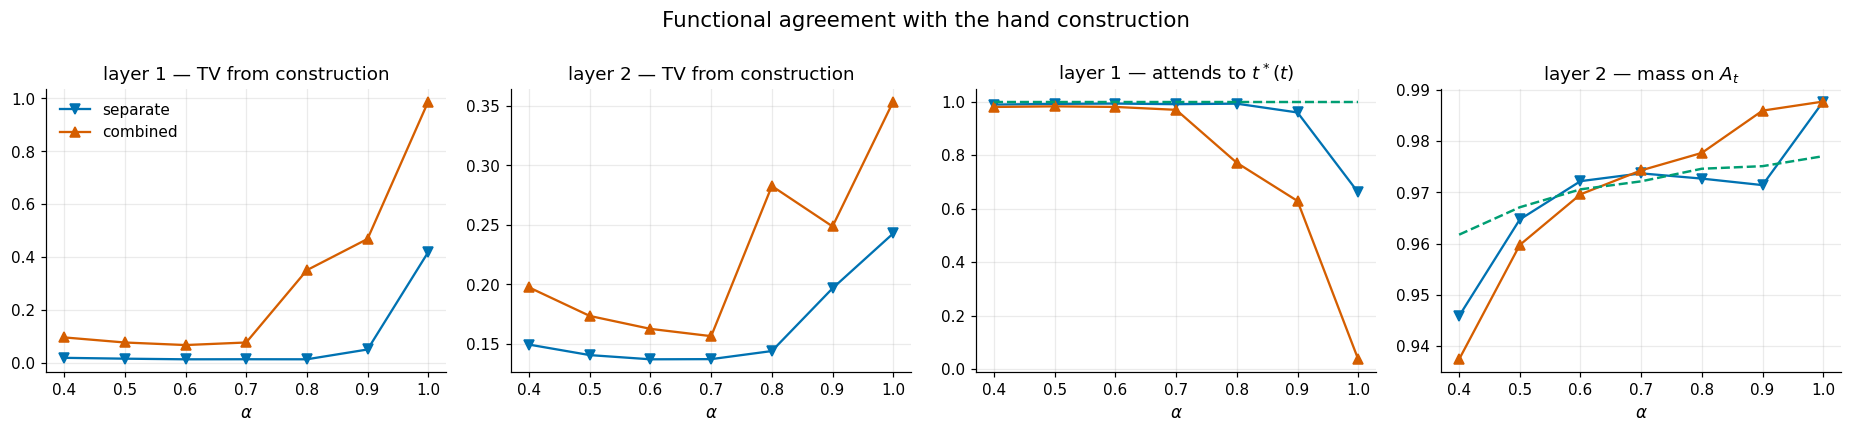

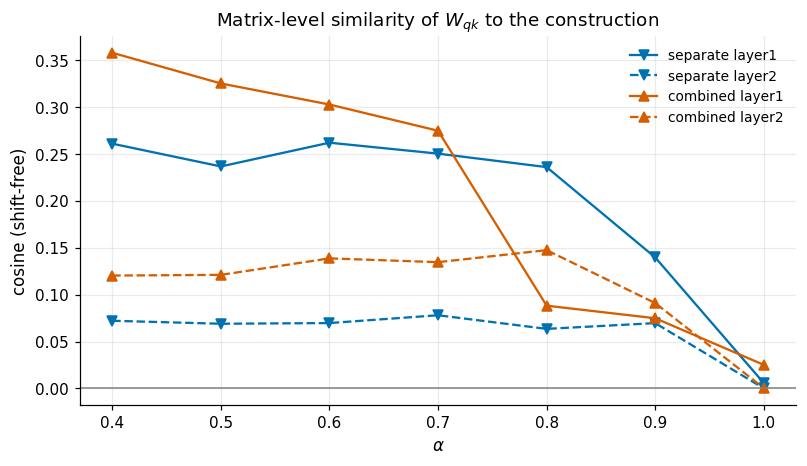

In [5]:
COL = {'separate': '#0072B2', 'combined': '#D55E00'}
MK  = {'separate': 'v', 'combined': '^'}
PANELS = [('tv_L1', 'layer 1 — TV from construction', None),
          ('tv_L2', 'layer 2 — TV from construction', None),
          ('L1_hit', 'layer 1 — attends to $t^*(t)$', 'L1_hit_constr'),
          ('L2_massA_learned', 'layer 2 — mass on $A_t$', 'L2_massA_constr')]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.0))
for ax, (key, title, ref) in zip(axes, PANELS):
    for arch in ARCHS:
        ys = [r[key] for r in ROWS if r['arch'] == arch]
        ax.plot(THRS, ys, marker=MK[arch], color=COL[arch], ms=7, label=arch)
    if ref:
        ax.plot(THRS, [r[ref] for r in ROWS if r['arch'] == ARCHS[0]], ls='--', lw=1.6,
                color='#009E73', label='construction')
    ax.set_title(title); ax.set_xlabel(r'$\alpha$'); ax.set_xticks(THRS)
axes[0].legend(loc='best')
fig.suptitle('Functional agreement with the hand construction')
fig.tight_layout(); fig.savefig(os.path.join(ART, 'functional_agreement.png'),
                                bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for arch in ARCHS:
    for i, ls in ((1, '-'), (2, '--')):
        ax.plot(THRS, COSD[(arch, i)], ls=ls, marker=MK[arch], color=COL[arch], ms=6,
                label=f'{arch} layer{i}')
ax.axhline(0, color='0.5', lw=1)
ax.set_xlabel(r'$\alpha$'); ax.set_ylabel('cosine (shift-free)'); ax.set_xticks(THRS)
ax.set_title(r'Matrix-level similarity of $W_{qk}$ to the construction')
ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(ART, 'wqk_cosine.png'), bbox_inches='tight')
plt.show()

## 6. The interpretable blocks of $W_{qk}$

Two blocks carry the whole circuit and are small enough to look at directly.

**Layer 1**, the position–position block (rows/cols 8:108): the construction is
$P_{t_k,t_q}=-20(t_q-t_k)$ off the diagonal and $-10^9$ on it — a smooth ramp with a killed
diagonal. Only the first 40 positions are shown.

**Layer 2**, the block (own token 0:8) $\times$ (layer-1 predecessor 108:116): the construction
is $1000\sqrt D\,I_4$ in the top-left $4\times4$ — match the current token against the
predecessor stored by layer 1.

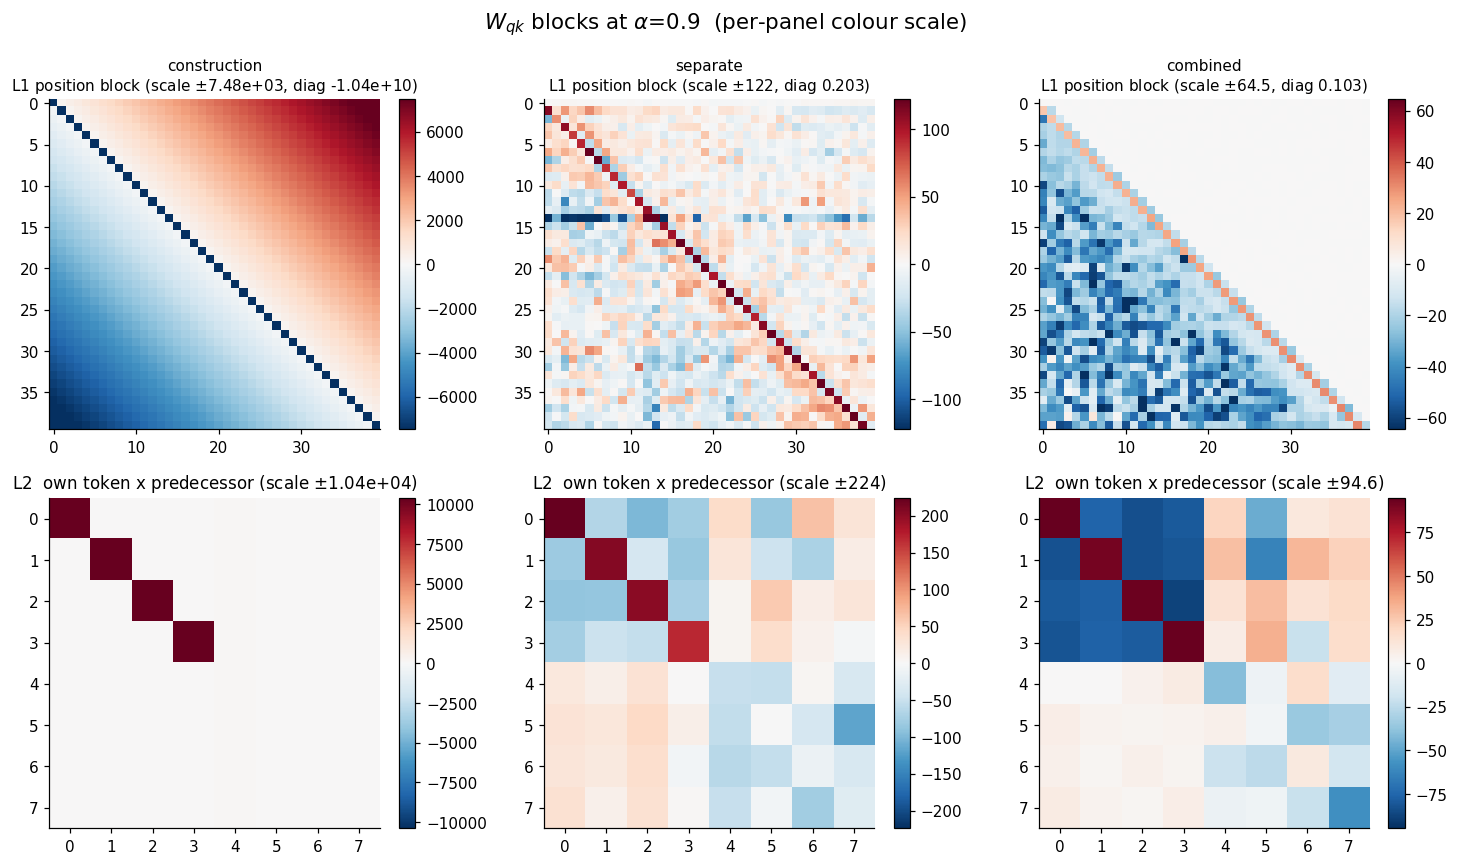

In [6]:
PLOT_THR = THRS[5]
N1 = 40
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0))
mats = [('construction', CQK)] + [(a, eff_qk(load(a, PLOT_THR))) for a in ARCHS]
for j, (name, qk) in enumerate(mats):
    b1 = qk[0][V:V + N1, V:V + N1].cpu().numpy()
    # scale from the OFF-diagonal only: the construction's self-attention kill is -1e9*sqrt(D),
    # six orders above the recency ramp, and would otherwise flatten the whole panel to white
    offd = np.abs(b1[~np.eye(N1, dtype=bool)])
    v = np.quantile(offd, 0.99) or 1.0
    im = axes[0][j].imshow(b1, cmap='RdBu_r', vmin=-v, vmax=v)
    axes[0][j].set_title(f'{name}\nL1 position block (scale $\\pm${v:.3g}, '
                         f'diag {b1[0, 0]:.3g})', fontsize=10)
    plt.colorbar(im, ax=axes[0][j], fraction=.046)
    b2 = qk[1][:V, D:D + V].cpu().numpy()
    v2 = np.abs(b2).max() or 1.0
    im2 = axes[1][j].imshow(b2, cmap='RdBu_r', vmin=-v2, vmax=v2)
    axes[1][j].set_title(f'L2  own token x predecessor (scale $\\pm${v2:.3g})', fontsize=11)
    axes[1][j].set_xticks(range(V)); axes[1][j].set_yticks(range(V))
    plt.colorbar(im2, ax=axes[1][j], fraction=.046)
for ax in axes.ravel():
    ax.grid(False)
fig.suptitle(rf'$W_{{qk}}$ blocks at $\alpha$={PLOT_THR}  (per-panel colour scale)')
fig.tight_layout(); fig.savefig(os.path.join(ART, 'wqk_blocks.png'), bbox_inches='tight')
plt.show()

In [7]:
print(f'diagonal dominance of the L2 (own token x predecessor) block, alpha={PLOT_THR}')
print(f'{"model":14s} {"diag mean":>11s} {"offdiag mean":>13s} {"ratio":>8s} {"cos with I_4":>13s}')
I4 = torch.eye(VS, device=DEV)
for name, qk in mats:
    b = qk[1][:VS, D:D + VS]
    dg = float(b.diagonal().abs().mean())
    of = float((b - torch.diag(b.diagonal())).abs().mean())
    ratio = 'inf' if of == 0 else f'{dg/of:.2f}'
    print(f'{name:14s} {dg:11.4g} {of:13.4g} {ratio:>8s} {cos(b, I4):13.4f}')

print('\nL1 recency: correlation of the off-diagonal position block with the CONSTRUCTION\'s')
off = ~torch.eye(T, dtype=torch.bool, device=DEV)
ref = CQK[0][V:, V:][off].flatten()
ref = ref - ref.mean()
for name, qk in mats:
    a_ = qk[0][V:, V:][off].flatten()
    a_ = a_ - a_.mean()
    print(f'  {name:14s} pearson r = {float((a_*ref).sum()/(a_.norm()*ref.norm()+1e-30)):+.4f}')

diagonal dominance of the L2 (own token x predecessor) block, alpha=0.9
model            diag mean  offdiag mean    ratio  cos with I_4
construction     1.039e+04             0      inf        1.0000
separate             199.8         54.67     3.65        0.8355
combined             92.87         60.39     1.54        0.5539

L1 recency: correlation of the off-diagonal position block with the CONSTRUCTION's
  construction   pearson r = +1.0000
  separate       pearson r = +0.1250
  combined       pearson r = +0.4459


## 7. Verdict

In [8]:
print('OV circuit: frozen to the construction, verified exact in every run.\n')
print('QK circuit — mean over thresholds:')
print(f'{"arch":9s} {"cos L1":>8s} {"cos L2":>8s} {"TV L1":>8s} {"TV L2":>8s} '
      f'{"L1 hit":>8s} {"L2 massA":>9s} {"best_test":>10s}')
for arch in ARCHS:
    rs = [r for r in ROWS if r['arch'] == arch]
    bt = np.mean([json.load(open(os.path.join(CDIR, f'metrics_{arch}_seed0_x_{t}.json')))
                  ['best_test'] for t in THRS])
    print(f'{arch:9s} {np.mean(COSD[(arch,1)]):8.4f} {np.mean(COSD[(arch,2)]):8.4f} '
          f'{np.mean([r["tv_L1"] for r in rs]):8.4f} {np.mean([r["tv_L2"] for r in rs]):8.4f} '
          f'{np.mean([r["L1_hit"] for r in rs]):8.4f} '
          f'{np.mean([r["L2_massA_learned"] for r in rs]):9.4f} {bt:10.4f}')
print(f'{"construction":9s} {1.0:8.4f} {1.0:8.4f} {0.0:8.4f} {0.0:8.4f} '
      f'{np.mean([r["L1_hit_constr"] for r in ROWS if r["arch"]==ARCHS[0]]):8.4f} '
      f'{np.mean([r["L2_massA_constr"] for r in ROWS if r["arch"]==ARCHS[0]]):9.4f}')

import csv
p = os.path.join(ART, 'qk_vs_construction.csv')
keys = ['arch', 'thr', 'tv_L1', 'tv_L2', 'argmax_L1', 'argmax_L2', 'L1_hit',
        'L1_hit_constr', 'L2_massA_learned', 'L2_massA_constr']
with open(p, 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=keys, extrasaction='ignore')
    w.writeheader(); w.writerows(ROWS)
print(f'\nwrote {p}')

OV circuit: frozen to the construction, verified exact in every run.

QK circuit — mean over thresholds:
arch        cos L1   cos L2    TV L1    TV L2   L1 hit  L2 massA  best_test
separate    0.1989   0.0604   0.0778   0.1639   0.9391    0.9697     1.4481
combined    0.2071   0.1078   0.3033   0.2250   0.7637    0.9703     1.4540
construction   1.0000   1.0000   0.0000   0.0000   1.0000    0.9712

wrote artifacts/qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000/qk_vs_construction.csv


---

## 8. Cross-entropy vs $\alpha$

Five curves per panel, train and test side by side:

| curve | what it is |
|---|---|
| ideal-$\alpha$ | knows the true 2-successor table; $\alpha/2$ on each. The CE floor. |
| ctx-count | empirical counts $+\varepsilon$, renormalised, $\times\alpha$, plus the exact noise floor |
| construction | this notebook's `ref_model` — the simplified architecture with $W_{qk}$ set to the hand construction |
| separate / combined | the trained QK-only models, from their best-train checkpoints |

`ideal-`$\alpha$ and `ctx-count` are read from the cache written by `analyse_equiprobable.ipynb`
(same dataset, same scoring window). Everything else is recomputed here on the full splits.

The construction here uses the *simplified* readout — bias before the log, no FFN — but that is
algebraically the same predictor as the earlier logit-space version whenever the noise slots are
zero, since $b_{\text{noise}} = e^{\beta}$. Its CE should therefore reproduce the value cached
under `construction`, which is checked below.

In [9]:
CACHE = os.path.join('artifacts', 'equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000',
                     'curves.json')
cache = json.load(open(CACHE))
SPLITS = ['train', 'test']

@torch.no_grad()
def full_ce(model, split, thr, batch=256):
    b = torch.load(os.path.join(DATA, split, f'data_x_{thr}.pt'), weights_only=False)
    x, y = b['x'], b['y']
    tot = n = 0.0
    for i in range(0, x.shape[0], batch):
        xb = x[i:i + batch].to(DEV); yb = y[i:i + batch, TS:TE].to(DEV)
        tot += F.cross_entropy(model(xb)[:, TS:TE].reshape(-1, V), yb.reshape(-1),
                               reduction='sum').item()
        n += yb.numel()
    return tot / n

KEYS = ['ideal', 'ctx', 'construction', 'separate', 'combined']
CE = {sp: {k: [] for k in KEYS} for sp in SPLITS}
print(f'{"split":>5s} {"thr":>4s} ' + ' '.join(f'{k:>13s}' for k in KEYS))
for sp in SPLITS:
    for thr in THRS:
        e = cache[f'{sp}|{thr}|eps0.01']
        CE[sp]['ideal'].append(e['ideal'])
        CE[sp]['ctx'].append(e['ctx'])
        CE[sp]['construction'].append(full_ce(ref_model(thr), sp, thr))
        for a in ARCHS:
            CE[sp][a].append(full_ce(load(a, thr), sp, thr))
        print(f'{sp:>5s} {thr:4.1f} ' + ' '.join(f'{CE[sp][k][-1]:13.4f}' for k in KEYS),
              flush=True)
    print()

d = max(abs(CE[sp]['construction'][i] - cache[f'{sp}|{t}|eps0.01']['construction'])
        for sp in SPLITS for i, t in enumerate(THRS))
print(f'simplified construction vs the cached logit-space one: max|diff| = {d:.2e}')

split  thr         ideal           ctx  construction      separate      combined


train  0.4        1.7822        1.8442        1.8439        1.8318        1.8349


train  0.5        1.7328        1.7850        1.7888        1.7789        1.7810


train  0.6        1.6436        1.6890        1.6968        1.6878        1.6893


train  0.7        1.5118        1.5523        1.5636        1.5545        1.5557


train  0.8        1.3324        1.3701        1.3842        1.3754        1.3857


... (6 outputs left out)

 test  0.8        1.3315        1.3687        1.3830        1.3811        1.3930


 test  0.9        1.0862        1.1203        1.1374        1.1387        1.1415


 test  1.0        0.6931        0.7265        0.7463        0.7407        0.7543



simplified construction vs the cached logit-space one: max|diff| = 6.15e-06


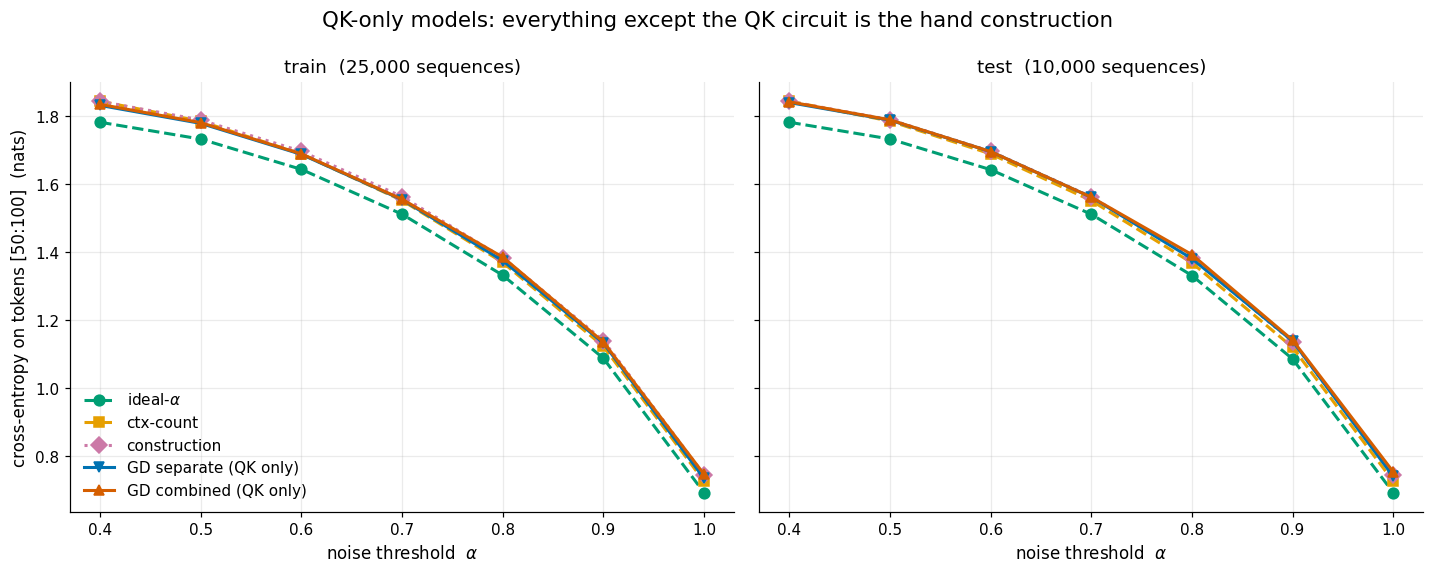

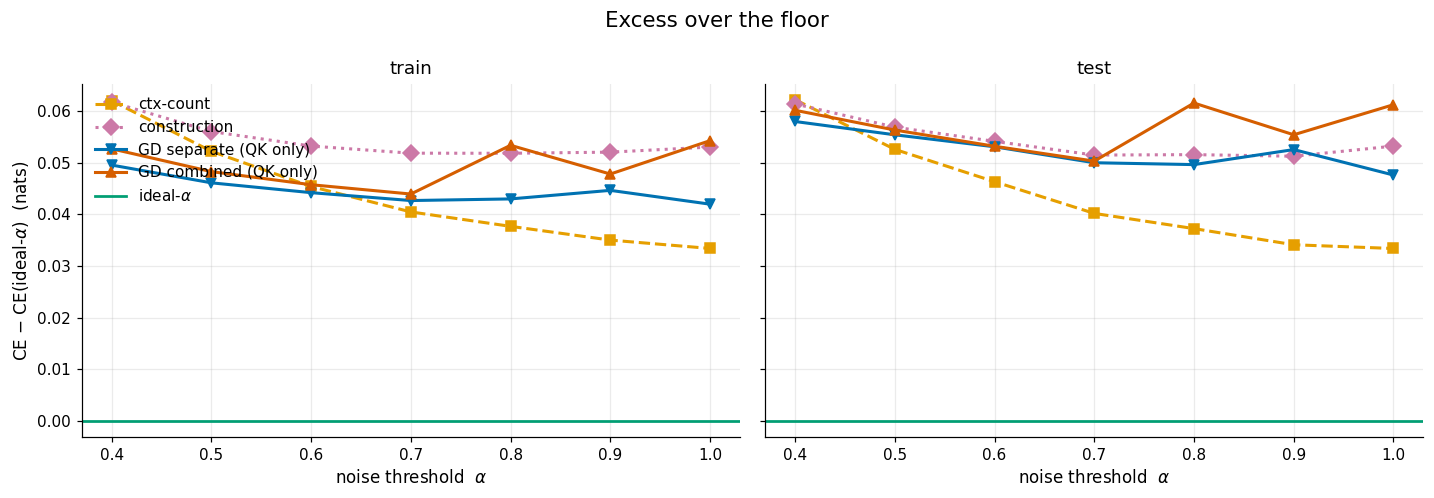

In [10]:
SER = {'ideal':        dict(color='#009E73', marker='o', ls='--', label=r'ideal-$\alpha$'),
       'ctx':          dict(color='#E69F00', marker='s', ls='--', label=r'ctx-count'),
       'construction': dict(color='#CC79A7', marker='D', ls=':',  label='construction'),
       'separate':     dict(color='#0072B2', marker='v', ls='-',  label='GD separate (QK only)'),
       'combined':     dict(color='#D55E00', marker='^', ls='-',  label='GD combined (QK only)')}

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.3), sharey=True)
for ax, sp in zip(axes, SPLITS):
    for k in KEYS:
        ax.plot(THRS, CE[sp][k], ms=7, lw=2.0, **SER[k])
    n = torch.load(os.path.join(DATA, sp, f'data_x_{THRS[0]}.pt'),
                   weights_only=False)['x'].shape[0]
    ax.set_title(f'{sp}  ({n:,} sequences)')
    ax.set_xlabel(r'noise threshold  $\alpha$'); ax.set_xticks(THRS)
axes[0].set_ylabel(f'cross-entropy on tokens [{TS}:{TE}]  (nats)')
axes[0].legend(loc='lower left')
fig.suptitle('QK-only models: everything except the QK circuit is the hand construction')
fig.tight_layout(); fig.savefig(os.path.join(ART, 'ce_vs_alpha.png'), bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6), sharey=True)
for ax, sp in zip(axes, SPLITS):
    base = np.array(CE[sp]['ideal'])
    for k in KEYS[1:]:
        ax.plot(THRS, np.array(CE[sp][k]) - base, ms=7, lw=2.0, **SER[k])
    ax.axhline(0, color='#009E73', lw=1.8, label=r'ideal-$\alpha$')
    ax.set_title(sp); ax.set_xlabel(r'noise threshold  $\alpha$'); ax.set_xticks(THRS)
axes[0].set_ylabel(r'CE $-$ CE(ideal-$\alpha$)  (nats)')
axes[0].legend(loc='upper left')
fig.suptitle('Excess over the floor')
fig.tight_layout(); fig.savefig(os.path.join(ART, 'excess_ce.png'), bbox_inches='tight')
plt.show()

In [11]:
LBL = {'ideal': 'ideal', 'ctx': 'ctx-count', 'construction': 'construction',
       'separate': 'separate', 'combined': 'combined'}
hdr = f'{"thr":>5s} | ' + ' | '.join(f'{LBL[k]:>21s}' for k in KEYS)
print(hdr); print(f'{"":>5s} | ' + ' | '.join(f'{"train":>10s} {"test":>10s}' for _ in KEYS))
print('-' * len(hdr))
rows = []
for i, t in enumerate(THRS):
    r = {'threshold': t}
    for k in KEYS:
        r[f'{k}_train'] = round(CE['train'][k][i], 6)
        r[f'{k}_test'] = round(CE['test'][k][i], 6)
    rows.append(r)
    print(f'{t:5.1f} | ' + ' | '.join(
        f'{CE["train"][k][i]:10.4f} {CE["test"][k][i]:10.4f}' for k in KEYS))

p = os.path.join(ART, 'ce_vs_alpha.csv')
with open(p, 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
print(f'\nwrote {p}\n')

print('combined - separate  (positive = separate better):')
for sp in SPLITS:
    d_ = np.array(CE[sp]['combined']) - np.array(CE[sp]['separate'])
    print(f'  {sp:5s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d_)) +
          f'   | mean {d_.mean():+.4f}  separate ahead {int((d_ > 0).sum())}/{len(d_)}')
print('\nmodel - construction  (negative = the trained model beats the hand circuit):')
for sp in SPLITS:
    for a in ARCHS:
        d_ = np.array(CE[sp][a]) - np.array(CE[sp]['construction'])
        print(f'  {sp:5s} {a:9s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d_)))

  thr |                 ideal |             ctx-count |          construction |              separate |              combined
      |      train       test |      train       test |      train       test |      train       test |      train       test
-----------------------------------------------------------------------------------------------------------------------------
  0.4 |     1.7822     1.7822 |     1.8442     1.8444 |     1.8439     1.8436 |     1.8318     1.8402 |     1.8349     1.8423
  0.5 |     1.7328     1.7330 |     1.7850     1.7856 |     1.7888     1.7899 |     1.7789     1.7884 |     1.7810     1.7893
  0.6 |     1.6436     1.6428 |     1.6890     1.6891 |     1.6968     1.6969 |     1.6878     1.6959 |     1.6893     1.6960
  0.7 |     1.5118     1.5117 |     1.5523     1.5518 |     1.5636     1.5631 |     1.5545     1.5616 |     1.5557     1.5619
  0.8 |     1.3324     1.3315 |     1.3701     1.3687 |     1.3842     1.3830 |     1.3754     1.3811 |     1.3857    